In [ ]:
"""
   Installing openlside package for reading WSI file
"""
!pip install openslide-python==1.4.1

In [ ]:
"""
  Installing other dependencies for openslide
"""
!apt-get update -qq
!apt-get install -y openslide-tools

In [ ]:
"""
  Command for mounting the drive.
"""
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
"""
   Changing the directory to the required working directory. Please change the
   path accordingly where this source file save on the Google drive.
"""
%cd '/content/drive/My Drive/2_PHDWork/1_Objective-I/4_Enlargement_Strategy/1_ComparisonStudy/'

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from openslide import OpenSlide

In [ ]:
"""
  The variables specifying which samples to be used and their loactions
"""

# Samples for dataset [PANDA, CPTAC-UCEC, CPTAC-CM]
samples = ["006f6aa35a78965c92fffd1fbd53a058","C3L-00136-21","C3L-00629-23"]

# Locations for PANDA dataset images.
panda_wsi = "../../../2_Objective-II/0_Dataset/1_Panda/train_images/radboud/" + samples[0] + ".tiff"
panda_grd_truth = "../../../2_Objective-II/0_Dataset/1_Panda/train_label_masks/radboud/" + samples[0] + "_mask.tiff"
prop_method_panda_mask = "./0_Generated_Mask/proposed_method/5_PANDA/1_dataset_based/" + samples[0] + "_predicted_mask.png"
lazyslide_panda_mask = "./0_Generated_Mask/lazyslide_method/5_PANDA/" + samples[0] + "_predicted_mask.png"
tia_panda_mask = "./0_Generated_Mask/tiatoolbox_method/5_PANDA/" + samples[0] + "_predicted_mask.png"

# Locations for CPTAC-UCEC images
cptac_uec_wsi = "../../0_Dataset/1_Dataset/0_Pure/4_CPTAC-UCEC/" + samples[1] + ".svs"
cptac_uec_grd_truth = "../../0_Dataset/1_Dataset/2_Masks/4_CPTAC-UCEC/PNG/" + samples[1] + "_mask.png"
prop_method_cptac_uec_mask = "./0_Generated_Mask/proposed_method/4_CPTAC-UCEC/" + samples[1] + "_predicted_mask.png"
lazyslide_cptac_uec_mask = "./0_Generated_Mask/lazyslide_method/4_CPTAC-UCEC/" + samples[1] + "_predicted_mask.png"
tia_cptac_uec_mask = "./0_Generated_Mask/tiatoolbox_method/4_CPTAC-UCEC/" + samples[1] + "_predicted_mask.png"

# Location for CPTAC-CM image
cptac_cm_wsi = "../../0_Dataset/1_Dataset/0_Pure/1_CPTAC-CM/" + samples[2] + ".svs"
cptac_cm_grd_truth = "../../0_Dataset/1_Dataset/2_Masks/1_CPTAC-CM/PNG/" + samples[2] + "_mask.png"
prop_method_cptac_cm_mask = "./0_Generated_Mask/proposed_method/1_CPTAC-CM/" + samples[2] + "_predicted_mask.png"
lazyslide_cptac_cm_mask = "./0_Generated_Mask/lazyslide_method/1_CPTAC-CM/" + samples[2] + "_predicted_mask.png"
tia_cptac_cm_mask = "./0_Generated_Mask/tiatoolbox_method/1_CPTAC-CM/" + samples[2] + "_predicted_mask.png"

# Output path
output_path = "./output_images/"


In [ ]:
"""
  Method to generate a figure which shows WSI samples from each dataset (PANDA,
  CPTAC-UCEC and CPTAC-CM) and their tissue masks generate by each method. It
  saves the figure to the desired folder.

  Parameter:
        None
  Return:
        None
"""
def generate_method_comaprison_sample_figure():
  # Data for each row (sample)
  data_rows = [
    {
        "wsi": panda_wsi,
        "groud_truth": panda_grd_truth,
        "prop_mask": prop_method_panda_mask,
        "lazy_mask": lazyslide_panda_mask,
        "tia_mask": tia_panda_mask,
        "row_label": "PANDA Sample",
        "dataset": "PANDA",
        "output_path": "./output_images/"
    },
    {
        "wsi": cptac_uec_wsi,
        "groud_truth": cptac_uec_grd_truth,
        "prop_mask": prop_method_cptac_uec_mask,
        "lazy_mask": lazyslide_cptac_uec_mask,
        "tia_mask": tia_cptac_uec_mask,
        "row_label": "CPTAC-UCEC Sample",
        "dataset": "CPTAC-UCEC",
        "output_path": "./output_images/"
    },
    {
        "wsi": cptac_cm_wsi,
        "groud_truth": cptac_cm_grd_truth,
        "prop_mask": prop_method_cptac_cm_mask,
        "lazy_mask": lazyslide_cptac_cm_mask,
        "tia_mask": tia_cptac_cm_mask,
        "row_label": "CPTAC-CM Sample",
        "dataset": "CPTAC-CM",
        "output_path": "./output_images/"

    } ]


  # Create the figure with 3 rows and 4 columns
  fig, axes = plt.subplots(3, 5, figsize=(20, 15))

  # Define column titles
  col_titles = [
    "Level-0 WSI",
    "Ground-truth Mask",
    "Mask from Proposed Method",
    "Mask from LazySlide",
    "Mask from TIAToolbox"
   ]

  # Set column titles for the first row of subplots
  for i, title in enumerate(col_titles):
    axes[0, i].set_title(title, fontsize=14, fontweight='bold')


  # Populate the subplots with images
  for r_idx, row_data in enumerate(data_rows):
    # if(r_idx != 0):
    #   continue
    populate_figure_rows(row_data,[axes[r_idx,0],axes[r_idx,1],axes[r_idx,2],axes[r_idx,3],axes[r_idx,4]])

  outfile = output_path + "method_comparison_sample_figure.pdf"
  plt.savefig(outfile, dpi=300, bbox_inches="tight", format="pdf")
  plt.show()
  plt.close("all")
  return

"""
   Method to popolate images to each row of the figure.

   Parameters:
      row_data: the data regarding the image to be populated
      axes    : the axis to be populated

   Returns:
      None
"""
def populate_figure_rows(row_data,axes):
  populate_wsi_image(row_data,axes[0])
  populate_ground_truth_mask(row_data,axes[1])
  populate_prop_meth_pred_mask(row_data,axes[2])
  populate_lazyslide_pred_mask(row_data,axes[3])
  populate_tia_pred_mask(row_data,axes[4])
  return

"""
   Method to populate WSI image to the first column of the figure.

   Parameters:
      row_data : the data regarding the image to be populated
      ax       : the axis to be populated

   Returns:
      None
"""
def populate_wsi_image(row_data,ax):
  wsiname = row_data["wsi"]
  wsi = OpenSlide(wsiname)
  level =  0
  image = np.array(wsi.read_region((0,0),level,wsi.level_dimensions[level]))
  image = cv.cvtColor(image,cv.COLOR_RGBA2RGB)
  ax.imshow(image)
  ax.set_ylabel(row_data["row_label"], rotation=90, size='large', fontweight='bold')
  return

"""
  Method to populate ground truth mask to the second column of the figure.

  Parameters:
      row_data : the data regarding the image to be populated
      ax       : the axis to be populated

  Returns:
      None
"""
def populate_ground_truth_mask(row_data,ax):
  if(row_data["dataset"] == "PANDA"):
    level = 0
    mask_wsi  = OpenSlide(row_data["groud_truth"])
    full_mask = np.array(mask_wsi.read_region((0,0),level,
                                              mask_wsi.level_dimensions[level]))
    full_mask = (cv.cvtColor(full_mask,cv.COLOR_RGBA2RGB))[:,:,0]
    grd_truth_img = np.zeros((full_mask.shape[0],full_mask.shape[1]),dtype=np.uint8)
    grd_truth_img[full_mask > 0] = 255
  else:
    grd_truth_img = cv.imread(row_data["groud_truth"])

  ax.imshow(grd_truth_img,"gray")

  return

"""
   Method to populate proposed method mask to the second column of the figure.

   Parameters:
      row_data : the data regarding the image to be populated
      ax       : the axis to be populated

   Returns:
      None
"""
def populate_prop_meth_pred_mask(row_data,ax):
  prop_mask_img = cv.imread(row_data["prop_mask"])
  ax.imshow(prop_mask_img,"gray")
  return

"""
  Method to populate lazyslide method mask to the third column of the figure.

  Parameters:
      row_data : the data regarding the image to be populated
      ax       : the axis to be populated

  Returns:
      None
"""
def populate_lazyslide_pred_mask(row_data,ax):
  lazy_mask_img = cv.imread(row_data["lazy_mask"])
  ax.imshow(lazy_mask_img,"gray")
  return

"""
  Method to populate tia toolbox method mask to the fourth column of the figure.

  Parameters:
      row_data : the data regarding the image to be populated
      ax       : the axis to be populated

  Returns:
      None
"""
def populate_tia_pred_mask(row_data,ax):
  tia_mask_img = cv.imread(row_data["tia_mask"])
  ax.imshow(tia_mask_img,"gray")
  return

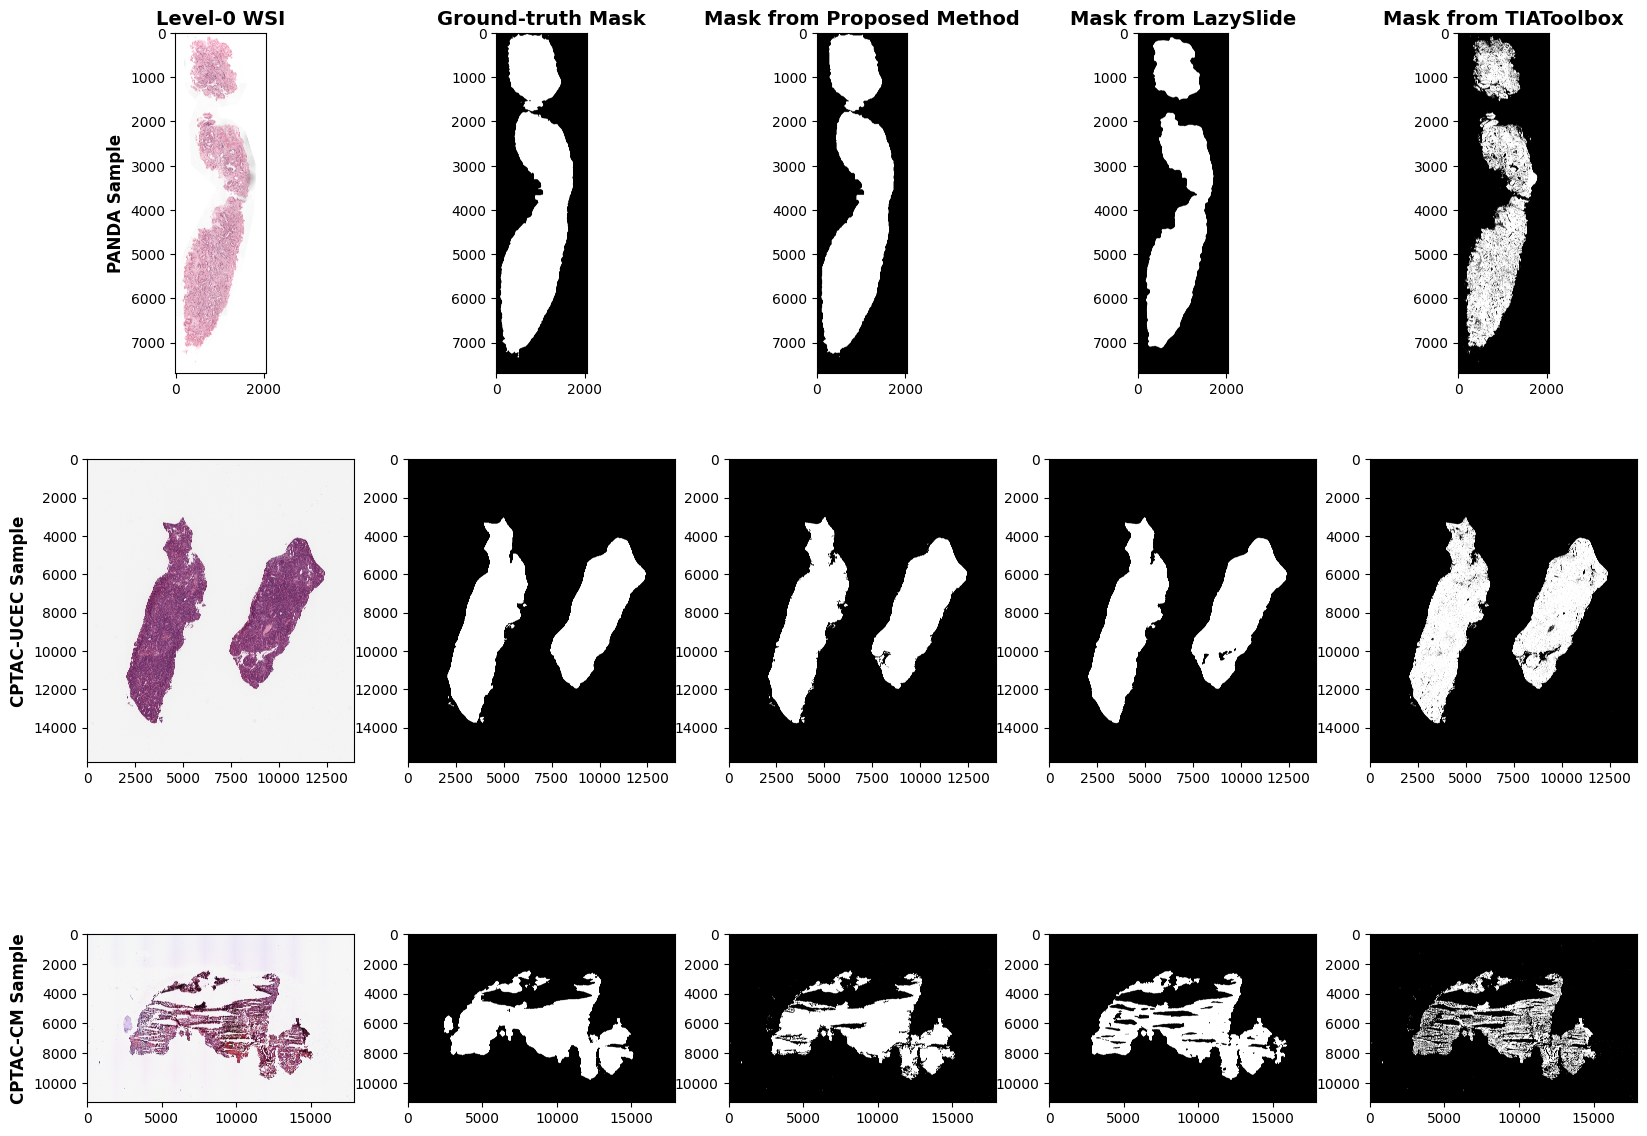

In [ ]:
"""
  Execute it to generate the required figure.
  Note: It took around 9 minutes to generate the image and the RAM required was
        around 9GB
"""
generate_method_comaprison_sample_figure()

In [ ]:
"""
  Method to save the images of the figure independently.

  Parameters:
      None
  Returns:
      None
"""
def save_each_image_independently():
  # Data for each row (sample)
  data_rows = [
    {
        "wsi": panda_wsi,
        "prop_mask": prop_method_panda_mask,
        "lazy_mask": lazyslide_panda_mask,
        "tia_mask": tia_panda_mask,
        "row_label": "Panda Sample",
        "dataset": "PANDA",
        "output_path": "./output_images/"
    },
    {
        "wsi": cptac_uec_wsi,
        "prop_mask": prop_method_cptac_uec_mask,
        "lazy_mask": lazyslide_cptac_uec_mask,
        "tia_mask": tia_cptac_uec_mask,
        "row_label": "CPTAC-UCEC Sample",
        "dataset": "CPTAC-UCEC",
        "output_path": "./output_images/"
    },
    {
        "wsi": cptac_cm_wsi,
        "prop_mask": prop_method_cptac_cm_mask,
        "lazy_mask": lazyslide_cptac_cm_mask,
        "tia_mask": tia_cptac_cm_mask,
        "row_label": "CPTAC-CM Sample",
        "dataset": "CPTAC-CM",
        "output_path": "./output_images/"

    } ]


  # Populate the subplots with images
  for r_idx, row_data in enumerate(data_rows):
    # if(r_idx != 0):
    #   continue
    populate_and_save_images(row_data)
    plt.close("all")

  return

"""
  Method to populate the image one-by-one and save it.

  Parameters:
       row_data:  the information about the images to be saved.

  Returns:
      None
"""
def populate_and_save_images(row_data):
  save_wsi_image(row_data)
  save_prop_meth_pred_mask(row_data)
  save_lazyslide_pred_mask(row_data)
  save_tia_pred_mask(row_data)
  return

"""
  Method to save the WSI image.

  Parameters:
      row_data:  the information about the images to be saved.

  Returns:
      None
"""
def save_prop_meth_pred_mask(row_data):
  prop_mask_img = cv.imread(row_data["prop_mask"])
  outputfile = row_data["output_path"] + row_data["dataset"] + "_Sample1_proposed_method_mask.png"
  plt.imshow(prop_mask_img,"gray")
  plt.savefig(outputfile, dpi=300, bbox_inches="tight")
  plt.show()
  plt.close()
  return

"""
  Method to save the proposed method mask.

  Parameters:
      row_data:  the information about the images to be saved.

  Returns:
      None
"""
def save_lazyslide_pred_mask(row_data):
  lazy_mask_img = cv.imread(row_data["lazy_mask"])
  outputfile = row_data["output_path"] + row_data["dataset"] + "_Sample1_lazyslide_method_mask.png"
  plt.imshow(lazy_mask_img,"gray")
  plt.savefig(outputfile, dpi=300, bbox_inches="tight")
  plt.show()
  plt.close()
  return

"""
  Method to save the lazyslide method mask.

  Parameters:
      row_data:  the information about the images to be saved.

  Returns:
      None
"""
def save_tia_pred_mask(row_data):
  tia_mask_img = cv.imread(row_data["tia_mask"])
  outputfile = row_data["output_path"] + row_data["dataset"] + "_Sample1_tia_method_mask.png")
  plt.imshow(tia_mask_img,"gray")
  plt.savefig(outputfile, dpi=300, bbox_inches="tight")
  plt.show()
  plt.close()
  return

"""
  Method to save the WSI image.

  Parameters:
      row_data:  the information about the images to be saved.

  Returns:
      None
"""
def save_wsi_image(row_data):
  wsiname = row_data["wsi"]
  wsi = OpenSlide(wsiname)
  level =  0
  image = np.array(wsi.read_region((0,0),level,wsi.level_dimensions[level]))
  image = cv.cvtColor(image,cv.COLOR_RGBA2RGB)
  outputfile = row_data["output_path"] + row_data["dataset"] + "_Sample1_WSI_image.png"
  plt.imshow(image)
  plt.savefig(outputfile, dpi=300, bbox_inches="tight")
  plt.show()
  plt.close()
  return

In [ ]:
"""
  Execute this if you want to save each image independently.
"""
save_each_image_independently()